# SecondLook | 09 Borrower personas

**Goal:** group the applicants the model does **not** approve into a few recognisable types, so the dashboard can say *who* SecondLook helps and *how*.

**Method** (`src/secondlook/personas.py`): K-Means clustering, an unsupervised method. It is never told who repaid; it only groups applicants whose features look alike. Everything runs in one scikit-learn `Pipeline`:

1. **Median imputation** fills the few missing values.
2. **StandardScaler** puts every feature on the same scale (mean 0, standard deviation 1). K-Means measures distance, so without scaling the feature with the biggest numbers would decide the clusters on its own.
3. **KMeans** with `random_state=42` (and 10 restarts) so the result is reproducible.

We then choose the number of clusters *k*, profile and name each cluster, check that age and gender don't drive them, and draw a 2D map with PCA.

## 1. Setup

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "secondlook").exists())
sys.path.insert(0, str(ROOT / "src"))

from secondlook import modeling as M
from secondlook import personas as PE
from secondlook.config import FIGURES_DIR, ID_COL, PROCESSED_DIR, TARGET_COL
from secondlook.fairness import add_groups
from secondlook.features import load_features
from secondlook.path import score_grid, summarise

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
F = PE.PERSONA_FEATURES

def save(fig, name):
    fig.savefig(FIGURES_DIR / f"{name}.png", bbox_inches="tight")

## 2. Who is not approved

All test applicants with PD at or above the 0.17 cutoff: the *under review* band (PD 0.17 to 0.22) and the declined. These are the people SecondLook is for. Same split and order as notebook 03, checked by the `assert`.

In [2]:
model, meta = M.load_model()
CUTOFF = meta["cutoff"]
_, test = M.split(load_features())
preds = pd.read_parquet(PROCESSED_DIR / "test_predictions.parquet")
assert (preds[ID_COL].values == test[ID_COL].values).all()      # same split, same order as notebook 03
test = test.assign(PD=preds["PD_LGBM"].values,                 # PD 0.17-0.22 is flagged under review
                   DECISION=np.where(preds["BORDERLINE"], "under_review", preds["DECISION"]))
na = test[test["PD"] >= CUTOFF].copy()
print(f"Test applicants: {len(test):,}   not approved (PD >= {CUTOFF}): {len(na):,} ({len(na) / len(test):.1%})")
print(na["DECISION"].value_counts().to_string())
print(f"Actually repaid: {1 - na[TARGET_COL].mean():.1%}")

Test applicants: 61,503   not approved (PD >= 0.17): 7,263 (11.8%)
DECISION
decline         4652
under_review    2611
Actually repaid: 71.3%


## 3. Path to approval for each of them

The path to approval from Step 8 (`path.py`): re-score the applicant with a smaller loan (up to 40% less) and/or more payments (up to 1.5x, within the 34.7-payment cap) and keep the smallest change that gets approved. The result is cached because it re-scores up to 54 loan variants for each of the 7,263 applicants.

In [3]:
if PE.PATHS_PATH.exists():
    paths = pd.read_parquet(PE.PATHS_PATH)
else:                                                     # about 10 seconds
    paths = summarise(score_grid(na, model, meta), CUTOFF)
    paths.to_parquet(PE.PATHS_PATH, index=False)
assert set(paths[ID_COL]) == set(na[ID_COL])
na = na.merge(paths[[ID_COL, "has_path", "rec_cut", "rec_term_mult"]], on=ID_COL, validate="1:1")
print(f"With a path to approval: {na['has_path'].mean():.1%}")
print(na.groupby("DECISION")["has_path"].mean().map("{:.1%}".format).to_string())

With a path to approval: 52.4%
DECISION
decline         31.3%
under_review    90.1%


## 4. The eight clustering features

Chosen to be **interpretable and non-sensitive**: no age, gender, family status or children. Each says something a loan officer could act on.

| Feature | What it captures |
|---|---|
| External credit score | The average of the three external scores, the model's strongest signal |
| Loan ÷ yearly income, Payment ÷ income | How big the loan is for this person |
| Number of payments | Loan length |
| Years in current job | Job stability |
| Share of past payments late | Past repayment behaviour at Home Credit |
| Has a bureau record, Loans at other lenders | How much credit history there is |

In [4]:
desc = na[F].describe(percentiles=[0.01, 0.5, 0.99]).T[["count", "mean", "std", "1%", "50%", "99%"]]
desc.insert(0, "Feature", [PE.FEATURE_LABELS[f] for f in F])
desc["missing"] = na[F].isna().mean()
desc.style.format({"count": "{:,.0f}", "missing": "{:.1%}", **{c: "{:.3f}" for c in ["mean", "std", "1%", "50%", "99%"]}})

,Feature,count,mean,std,1%,50%,99%,missing
EXT_SOURCE_MEAN,External credit score,"7,259",0.312,0.129,0.028,0.310,0.631,0.1%
CREDIT_TO_INCOME,Loan ÷ yearly income,"7,263",3.734,2.524,0.667,3.205,11.980,0.0%
ANNUITY_TO_INCOME,Payment ÷ income,"7,263",0.189,0.093,0.044,0.175,0.473,0.0%
CREDIT_TERM,Number of payments,"7,263",19.664,6.530,8.426,19.504,36.256,0.0%
YEARS_EMPLOYED,Years in current job,"6,767",3.991,3.956,0.281,2.784,20.222,6.8%
INST_LATE_SHARE,Share of past payments late,"7,046",0.122,0.147,0.000,0.074,0.583,3.0%
HAS_BUREAU_HISTORY,Has a bureau record,"7,263",0.791,0.407,0.000,1.000,1.000,0.0%
BUR_N_LOANS,Loans at other lenders,"7,263",4.480,4.901,0.000,3.000,21.000,0.0%


- **Missing values are few:** years in the job is missing for 6.8% (pensioners and others without a current employer), the late-payment share for 3.0% (no earlier Home Credit loans) and the external score for 0.1%. The median fills them.
- **Scales differ hugely:** loans at other lenders run from 0 to 56 and loan-to-income from 0.2 to 85, while the external score sits between 0 and 1. That is why the pipeline scales before clustering.
- A few features have long right tails (loan-to-income reaches 85x income). We kept the plain scaling the guide asks for; a log-transform version gave lower silhouette scores and no clearer clusters.

## 5. Choosing k: elbow plot and silhouette score together

- **Inertia** is the total squared distance from each applicant to its cluster centre. It always falls as k grows; we look for the *elbow* where adding clusters stops paying off.
- **Silhouette** (−1 to 1) compares how close each applicant is to its own cluster vs the nearest other cluster. Higher means better-separated clusters.

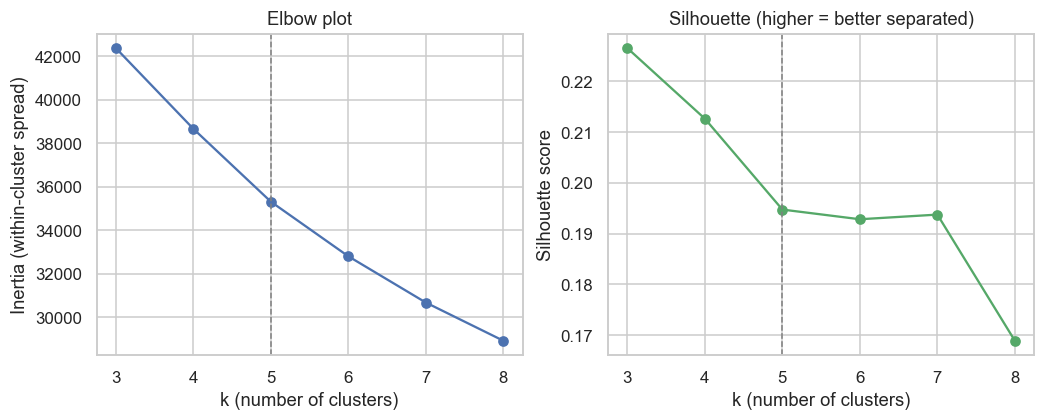

,inertia,silhouette,smallest cluster,inertia drop
k,,,,
3,"42,364",0.227,"1,429",nan%
4,"38,655",0.213,963,8.8%
5,"35,304",0.195,810,8.7%
6,"32,793",0.193,418,7.1%
7,"30,666",0.194,376,6.5%
8,"28,911",0.169,301,5.7%


In [5]:
scan = PE.scan_k(na[F])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(scan.index, scan["inertia"], marker="o")
axes[0].set(xlabel="k (number of clusters)", ylabel="Inertia (within-cluster spread)", title="Elbow plot")
axes[1].plot(scan.index, scan["silhouette"], marker="o", color="C2")
axes[1].set(xlabel="k (number of clusters)", ylabel="Silhouette score", title="Silhouette (higher = better separated)")
for ax in axes:
    ax.axvline(5, color="grey", ls="--", lw=1)
save(fig, "32_choose_k")
plt.show()
scan.assign(**{"inertia drop": -scan["inertia"].pct_change()}).style.format(
    {"inertia": "{:,.0f}", "silhouette": "{:.3f}", "inertia drop": "{:.1%}", "smallest cluster": "{:,}"})

**Reading the two charts together**

- **There is no sharp elbow.** Each extra cluster cuts inertia by a similar amount (8.8%, 8.7%, then 7.1%, 6.5%, 5.7%). The bend, such as it is, comes after k = 5, where the gain drops from 8.7% to 7.1%.
- **Silhouette is highest at k = 3 (0.227)**, then falls to a plateau of about 0.19 for k = 5 to 7, and drops at k = 8 (0.169).
- Scores around 0.2 mean the clusters overlap: borrowers form a continuum rather than neat islands, which is normal for real applicant data. So the choice of k is partly about which grouping is most **useful**.
- **We choose k = 5.** It is where the elbow bends and the silhouette plateau begins. k = 6 and 7 add small clusters (418 and 376 applicants) without better separation, and k = 3 or 4 is too coarse, as the next cell shows.

In [6]:
pipe = PE.make_pipeline(4).fit(na[F])
p4 = PE.profile(na.assign(persona=pipe[-1].labels_))
pipe = PE.make_pipeline(5).fit(na[F])
na["cluster"] = pipe[-1].labels_
p5 = PE.profile(na.assign(persona=na["cluster"]))
cols = ["Applicants", "EXT_SOURCE_MEAN", "CREDIT_TO_INCOME", "YEARS_EMPLOYED", "INST_LATE_SHARE", "HAS_BUREAU_HISTORY", "BUR_N_LOANS"]
print("k = 4"); display(p4[cols].round(3))
print("k = 5"); display(p5[cols].round(3))

k = 4


,Applicants,EXT_SOURCE_MEAN,CREDIT_TO_INCOME,YEARS_EMPLOYED,INST_LATE_SHARE,HAS_BUREAU_HISTORY,BUR_N_LOANS
persona,,,,,,,
0,963,0.315,3.125,8.439,0.067,0.988,11.0
1,3686,0.313,2.667,2.323,0.077,1.000,3.0
2,1396,0.286,3.161,2.609,0.083,0.000,0.0
3,1218,0.319,6.679,2.913,0.056,0.910,4.0


k = 5


,Applicants,EXT_SOURCE_MEAN,CREDIT_TO_INCOME,YEARS_EMPLOYED,INST_LATE_SHARE,HAS_BUREAU_HISTORY,BUR_N_LOANS
persona,,,,,,,
0,2983,0.299,2.667,2.267,0.026,1.000,4.0
1,810,0.315,3.160,9.366,0.071,0.984,11.0
2,1057,0.318,7.078,2.965,0.050,0.895,4.0
3,1066,0.368,2.984,2.749,0.333,0.956,3.0
4,1347,0.282,3.161,2.615,0.077,0.000,0.0


**Why not k = 4:** with four clusters there is no group of late payers; the highest median late share is 8%. With five, a distinct group appears whose median late share is **33%**, four times the others. That is a real, actionable type of applicant that k = 4 hides inside the other groups. The silhouette cost of the extra cluster is small (0.213 → 0.195).

## 6. Profile and name the five personas

Medians of each feature (share for *has a bureau record*), the actual repayment rate, the mean predicted PD, and the share with a path to approval. Each name comes from the one trait that sets the cluster apart (`name_personas`): the fewest bureau records, the highest late share, the highest loan-to-income, the longest job tenure, and the rest. Never age or gender.

In [7]:
names = PE.name_personas(p5)
na["persona"] = na["cluster"].map(names)
prof = PE.profile(na).sort_values("Applicants", ascending=False)
show = prof.rename(columns=PE.FEATURE_LABELS)
pct = ["Share", "Payment ÷ income", "Share of past payments late", "Has a bureau record", "Repayment rate", "Mean PD", "Path to approval"]
show.style.format({**{c: "{:.0%}" for c in pct}, "Applicants": "{:,}", "External credit score": "{:.3f}",
                   "Loan ÷ yearly income": "{:.1f}x", "Number of payments": "{:.0f}", "Years in current job": "{:.1f}",
                   "Loans at other lenders": "{:.0f}"})

,Applicants,Share,External credit score,Loan ÷ yearly income,Payment ÷ income,Number of payments,Years in current job,Share of past payments late,Has a bureau record,Loans at other lenders,Repayment rate,Mean PD,Path to approval
persona,,,,,,,,,,,,,
"Newer job, clean record","2,983",41%,0.299,2.7x,15%,18,2.3,3%,100%,4,71%,29%,51%
Thin file,"1,347",19%,0.282,3.2x,18%,18,2.6,8%,0%,0,72%,28%,54%
Missed payments before,"1,066",15%,0.368,3.0x,18%,16,2.7,33%,96%,3,70%,30%,51%
Big loan for the income,"1,057",15%,0.318,7.1x,28%,28,3.0,5%,89%,4,73%,27%,56%
"Long job, many past loans",810,11%,0.315,3.2x,15%,20,9.4,7%,98%,11,71%,27%,54%


**The five personas**

| Persona | Size | What sets it apart |
|---|---|---|
| **Newer job, clean record** | 2,983 (41%) | The largest group: about 2.3 years in their job, almost no late payments (3%), ordinary loans. Nothing stands out except external scores slightly below the median (0.299 vs 0.310) |
| **Thin file** | 1,347 (19%) | No bureau record at all; lowest external score (0.282) |
| **Missed payments before** | 1,066 (15%) | A third of past instalments paid late, but the **best** external scores (0.368) |
| **Big loan for the income** | 1,057 (15%) | Borrowing 7.1x yearly income, payments taking 28% of income, about 28 payments |
| **Long job, many past loans** | 810 (11%) | About 9.4 years in their job and 11 loans at other lenders |

**The key finding: the personas differ in *why* they are not approved, not in *how risky* they are.** Every persona repaid at 70% to 73% and has a mean PD of 27% to 30%. The model has already priced each one's risk, and about seven in ten of each group would have repaid. So the business value of the personas is in the **response**: what a second look should check, and which loan change helps.

In [8]:
# The descriptions make claims ("best external scores"): check them against the profile before using them
assert prof["EXT_SOURCE_MEAN"].idxmax() == "Missed payments before"
assert prof["Applicants"].idxmax() == "Newer job, clean record"
desc_text = {n: PE.describe(n, r) for n, r in prof.iterrows()}
for n, s in desc_text.items():
    print(f"{n}: {s}\n")

Newer job, clean record: The largest group: about 2 years in their job, few late payments and ordinary loans; not approved on scores rather than any single red flag. 71% actually repaid, and 51% have a path to approval by borrowing less or taking more payments.

Thin file: No record at any credit bureau, so the lender can't read them; otherwise ordinary loans. 72% actually repaid, and 54% have a path to approval by borrowing less or taking more payments.

Missed payments before: Paid 33% of past instalments late (median), but have the best external scores of the five groups. 70% actually repaid, and 51% have a path to approval by borrowing less or taking more payments.

Big loan for the income: Asking for 7.1x their yearly income, with payments taking 28% of income over about 28 payments. 73% actually repaid, and 56% have a path to approval by borrowing less or taking more payments.

Long job, many past loans: About 9 years in their job and 11 loans at other lenders: experienced, stabl

## 7. How SecondLook helps each persona

For the applicants with a path to approval: does the smallest approved change keep the loan amount (more payments only), keep the term (borrow less only), or need both?

In [9]:
wp = na[na["has_path"]]
by, byp = na.groupby("persona"), wp.groupby("persona")
how = pd.DataFrame({
    "Under review (PD 0.17-0.22)": by["DECISION"].apply(lambda s: (s == "under_review").mean()),
    "Path to approval": by["has_path"].mean(),
    "More payments only": byp["rec_cut"].apply(lambda s: (s == 0).mean()),
    "Borrow less only": byp["rec_term_mult"].apply(lambda s: (s == 1).mean()),
    "Median cut, if borrowing less": wp[wp["rec_cut"] > 0].groupby("persona")["rec_cut"].median(),
}).loc[prof.index]
how["Both"] = 1 - how["More payments only"] - how["Borrow less only"]
how.loc["All not approved"] = [(na["DECISION"] == "under_review").mean(), na["has_path"].mean(), (wp["rec_cut"] == 0).mean(),
                               (wp["rec_term_mult"] == 1).mean(), wp.loc[wp["rec_cut"] > 0, "rec_cut"].median(),
                               ((wp["rec_cut"] > 0) & (wp["rec_term_mult"] > 1)).mean()]
how.style.format("{:.0%}")

,Under review (PD 0.17-0.22),Path to approval,More payments only,Borrow less only,"Median cut, if borrowing less",Both
persona,,,,,,
"Newer job, clean record",35%,51%,29%,32%,10%,39%
Thin file,36%,54%,31%,32%,10%,36%
Missed payments before,31%,51%,39%,24%,15%,37%
Big loan for the income,42%,56%,14%,56%,10%,29%
"Long job, many past loans",37%,54%,25%,39%,15%,36%
All not approved,36%,52%,28%,36%,10%,36%


- **Big loan for the income** has the most paths (56%) and needs a **smaller loan**: 56% of its paths are *borrow less only* and just 14% *more payments only*, because its loans already run about 28 payments, close to the 34.7 cap. The typical cut is 10%.
- **Missed payments before** is the group where **more payments** works best (39% of paths), and when it needs a cut, a bigger one (median 15%). Smaller payments make each instalment easier to keep up with.
- **Thin file** and **Newer job, clean record** look like the average: about half have a path, split evenly between the options. For thin files the more important help is the human second look itself: 36% of them are in the under-review band, where a loan officer can weigh information the bureau doesn't have.
- **Under review** shares are similar (31% to 42%), with the big-loan group the most often borderline.

## 8. Do age or gender drive the personas?

Age and gender were **not** clustering features, but other features can stand in for them. We compare each persona's age and gender mix with all not-approved applicants, and measure the association with **Cramér's V** (0 = no link, 1 = the persona decides the group). For contrast, the same measure for *has a bureau record*, which **is** a clustering feature.

In [10]:
g = add_groups(na)
spread = pd.concat({
    "Median age": g.groupby("persona")["AGE_YEARS"].median().round(1),
    "Aged 20-29": g.groupby("persona")["Age band"].apply(lambda s: (s == "20-29").mean()),
    "Aged 50+": g.groupby("persona")["AGE_YEARS"].apply(lambda s: (s >= 50).mean()),
    "Male": g.groupby("persona")["Gender"].apply(lambda s: (s == "Male").mean()),
}, axis=1).loc[prof.index]
spread.loc["All not approved"] = [round(float(g["AGE_YEARS"].median()), 1), (g["Age band"] == "20-29").mean(),
                                  (g["AGE_YEARS"] >= 50).mean(), (g["Gender"] == "Male").mean()]
display(spread.style.format({"Median age": "{:.1f}", "Aged 20-29": "{:.0%}", "Aged 50+": "{:.0%}", "Male": "{:.0%}"}))
print("Median loan ÷ yearly income by gender:", g.groupby("Gender")["CREDIT_TO_INCOME"].median().astype(float).round(2).to_dict())
v = {"Age band": PE.cramers_v(g["persona"], g["Age band"]), "Gender": PE.cramers_v(g["persona"], g["Gender"].fillna("Unknown")),
     "Has a bureau record (a clustering feature)": PE.cramers_v(g["persona"], g["HAS_BUREAU_HISTORY"])}
pd.Series(v, name="Cramér's V with persona").round(3).to_frame()

,Median age,Aged 20-29,Aged 50+,Male
persona,,,,
"Newer job, clean record",35.0,30%,14%,49%
Thin file,34.5,31%,12%,51%
Missed payments before,35.6,26%,14%,47%
Big loan for the income,39.2,20%,22%,31%
"Long job, many past loans",42.1,9%,24%,37%
All not approved,36.5,26%,16%,45%


Median loan ÷ yearly income by gender: {'Female': 3.46, 'Male': 2.9}


,Cramér's V with persona
Age band,0.102
Gender,0.097
Has a bureau record (a clustering feature),0.932


- **Neither age nor gender defines a persona.** Cramér's V is **0.10** for age band and **0.10** for gender (weak), against **0.93** for the bureau record that the clustering does use. Every persona contains all ages and both genders.
- **Two personas lean one way, for understandable reasons:**
  - *Long job, many past loans* is older (median age 42.1 vs 36.5; only 9% in their 20s), because job tenure and the number of past loans both grow with age. The name describes the tenure and the loans, not the age.
  - *Big loan for the income* is 31% male vs 45% overall. It is defined by loan size relative to income, and among not-approved applicants women borrow more relative to income (median loan 3.5x yearly income vs 2.9x for men). We report it rather than hide it.
- Personas are a description for the dashboard, not a decision input. No applicant is approved or declined because of their persona.

## 9. A 2D map with PCA

The clusters live in 8 dimensions. **PCA** (principal component analysis) finds the two directions that keep the most spread in the scaled data, so we can draw them. The table below the map shows what each component measures (its *loadings*).

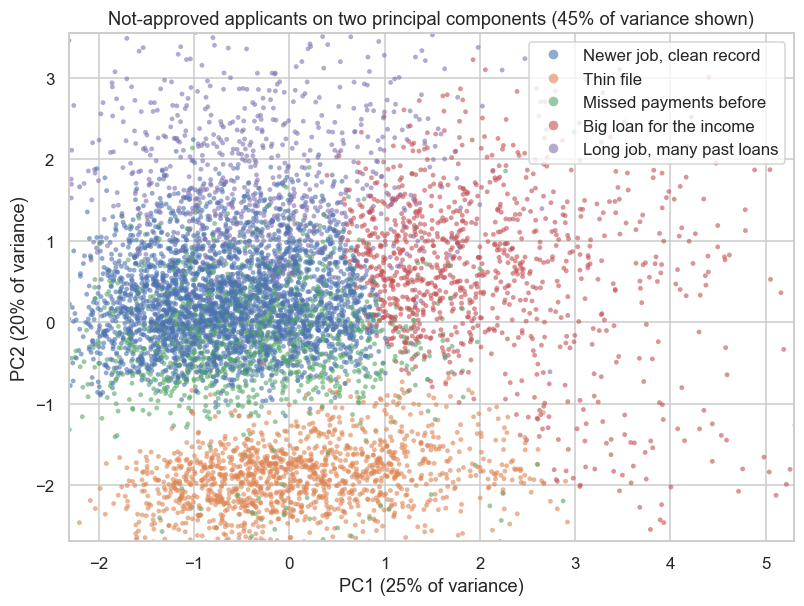

PC1 explains 25.1%, PC2 20.0%: together 45.1%


,PC1,PC2
External credit score,0.06,0.01
Loan ÷ yearly income,0.69,0.08
Payment ÷ income,0.59,-0.13
Number of payments,0.38,0.34
Years in current job,0.06,0.24
Share of past payments late,0.00,-0.15
Has a bureau record,-0.12,0.60
Loans at other lenders,-0.08,0.65


In [11]:
xy, var = PE.pca_map(pipe, na[F])
na["PC1"], na["PC2"] = xy[:, 0], xy[:, 1]
fig, ax = plt.subplots(figsize=(8.5, 6))
order = list(prof.index)
sns.scatterplot(data=na.sample(frac=1, random_state=42), x="PC1", y="PC2", hue="persona", hue_order=order, s=10, alpha=0.6,
                linewidth=0, ax=ax)
ax.set(xlabel=f"PC1 ({var[0]:.0%} of variance)", ylabel=f"PC2 ({var[1]:.0%} of variance)",
       title=f"Not-approved applicants on two principal components ({var.sum():.0%} of variance shown)")
lo, hi = np.percentile(xy, [0.5, 99.5], axis=0)
ax.set(xlim=(lo[0], hi[0]), ylim=(lo[1], hi[1]))
ax.legend(title="", markerscale=2, loc="best")
save(fig, "33_persona_map")
plt.show()
print(f"PC1 explains {var[0]:.1%}, PC2 {var[1]:.1%}: together {var.sum():.1%}")
pca = PCA(2, random_state=42).fit(pipe[:-1].transform(na[F]))
pd.DataFrame(pca.components_.T, index=[PE.FEATURE_LABELS[f] for f in F], columns=["PC1", "PC2"]).round(2)

- **The two components explain 45% of the variance** (25.1% and 20.0%), so the map is a useful sketch but leaves out over half the information.
- **PC1 is loan size for the income:** loan ÷ income (0.69), payment ÷ income (0.59) and number of payments (0.38). *Big loan for the income* sits to the right.
- **PC2 is credit history:** loans at other lenders (0.65) and has a bureau record (0.60). *Thin file* forms a band at the bottom and *Long job, many past loans* sits at the top.
- **Missed payments before overlaps the large central group** on this map because late payments load weakly on both components (−0.15 and 0.00). It is separated along a dimension the map doesn't show; that is the 55% of variance the two components leave out.

## 10. Save for the app

One row per not-approved applicant (persona, map coordinates, PD, outcome, path, the eight features), about 0.3 MB. The Portfolio Dashboard's *Personas* tab reads it, and the AI Analyst (Step 12) will query it.

In [12]:
out = na[[ID_COL, "persona", "PC1", "PC2", "PD", "DECISION", TARGET_COL, "has_path", *F]].copy()
for c in ["PC1", "PC2", "PD", *F]:
    out[c] = out[c].astype("float32")
out["persona"] = out["persona"].astype("category")
path = ROOT / "app" / "demo_data" / "personas.parquet"
out.to_parquet(path, index=False)
print(f"Saved {path.relative_to(ROOT)}: {len(out):,} rows, {path.stat().st_size / 1e3:.0f} KB")
print(f"PCA variance explained (for the app caption): {var[0]:.3f}, {var[1]:.3f}")

Saved app\demo_data\personas.parquet: 7,263 rows, 346 KB
PCA variance explained (for the app caption): 0.251, 0.200


## 11. Summary and limitations

**Answer:** the 7,263 not-approved test applicants fall into five personas: **Newer job, clean record** (41%), **Thin file** (19%), **Missed payments before** (15%), **Big loan for the income** (15%) and **Long job, many past loans** (11%). About 71% of every persona actually repaid, so none is a "bad" group. They differ in the reason for the decline and in the fix that works: a 10% smaller loan for the big-loan group, more payments for past late payers, and a human second look for thin files. Age and gender are only weakly linked to the personas (Cramér's V 0.10).

**Limitations**
- **Overlapping clusters** (silhouette about 0.2): personas are useful summaries, not sharp categories. Applicants near a boundary could fit two.
- **k = 5 is a judgement call** supported by both charts, not a unique answer. A different feature set would give different personas.
- **K-Means assumes round, similar-sized clusters** and is sensitive to outliers; the long-tailed features (loan-to-income up to 85x) pull some centres.
- **Built on one test split at one cutoff.** The dashboard's cutoff slider doesn't change the personas, which are fixed at the shipped cutoff of 0.17.